# Binning & Ranking transforms for omics matrices (per-sample)

This notebook takes a **wide matrix** like the one in your screenshot:

- **rows = samples** (e.g., `MDAMB468_BREAST`)
- **columns = proteins / genes** (e.g., `A2M`, `AAAS`, ...)
- **values = numeric measurements** (often log-normalized / z-scored)

It then computes two **per-sample** (row-wise) relative representations:

## 1) Quantile **binning** (with a special bin for zeros)
For each sample:
- values equal to **0** → bin **0**
- all **nonzero** values → split into **b quantiles** → bins **1..b**

## 2) **Ranking**
For each sample:
- sort features by value and assign **ranks** (ties get the average rank)

These transforms are useful when you want models to depend more on **within-sample relative patterns**
than on absolute scales (which can drift across batches/datasets).

---


In [10]:
# If you run this in a fresh environment, you may need:
# !pip install pandas numpy matplotlib pyarrow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import load, dump

np.random.seed(0)


## Load data

Supported formats: **.csv**, **.tsv/.txt**, **.parquet**, **.pkl**, **.joblib**

### Expected shape
- samples × features (e.g., 369 × 5113)

If the first column is sample IDs (strings), we’ll automatically use it as the index.


In [11]:
DATA_PATH = "data/transcriptomics_filtered.joblib"  # <-- set this to your file path, e.g. "data/proteomics_matrix.csv"

def load_matrix(path: str) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path.resolve()}")

    ext = path.suffix.lower()

    if ext == ".csv":
        df = pd.read_csv(path)
    elif ext == ".joblib":
        df = load(path)
    elif ext in [".tsv", ".txt"]:
        df = pd.read_csv(path, sep="\t")
    elif ext == ".parquet":
        df = pd.read_parquet(path)
    elif ext in [".pkl", ".pickle"]:
        df = pd.read_pickle(path)
    else:
        raise ValueError(f"Unsupported extension: {ext}")

    # Heuristics to set sample IDs as index
    if "samples" in df.columns:
        df = df.set_index("samples")
    else:
        first = df.columns[0]
        # common pattern when saving dataframes
        if str(first).startswith("Unnamed") or str(first).strip() == "":
            df = df.set_index(first)
        else:
            # If first col looks like IDs (non-numeric) and most others look numeric, set it as index
            if (not pd.api.types.is_numeric_dtype(df[first])):
                numeric_ratio = df.drop(columns=[first]).apply(pd.to_numeric, errors="coerce").notna().mean().mean()
                if numeric_ratio > 0.95:
                    df = df.set_index(first)

    # Force numeric feature matrix
    df = df.apply(pd.to_numeric, errors="coerce")
    return df

# Load
df = load_matrix(DATA_PATH)
df.shape, df.index.name, df.columns.name


((369, 22614), 'samples', 'genes')

In [12]:
df.head()

genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697


## Quick sanity checks
We’ll look at missingness, basic value ranges, and whether the data is already z-scored-ish.


In [13]:
missing_frac = df.isna().mean().mean()
val_min, val_max = np.nanmin(df.to_numpy()), np.nanmax(df.to_numpy())

# Rough check: if values look standardized across the whole matrix
flat = df.to_numpy().ravel()
flat = flat[~np.isnan(flat)]
flat_mean = float(np.mean(flat))
flat_std = float(np.std(flat))

print(f"Shape: {df.shape}")
print(f"Missing fraction (overall): {missing_frac:.4f}")
print(f"Value range: [{val_min:.4g}, {val_max:.4g}]")
print(f"Overall mean/std: {flat_mean:.4g} / {flat_std:.4g}")


Shape: (369, 22614)
Missing fraction (overall): 0.0000
Value range: [0, 17.25]
Overall mean/std: 2.592 / 2.413


## Core transforms: binning and ranking

### Binning details (matches the “quantile bins per sample” idea)
- We treat exact zeros as a special state: **bin 0**
- For nonzero values, we assign **approximately equal-frequency bins** using within-sample ranks.

This rank-based bin assignment is robust even when many values are identical (ties).


In [14]:
def bin_by_quantiles_per_sample(
    df: pd.DataFrame,
    b: int = 20,
    zero_bin: bool = True,
) -> pd.DataFrame:
    """Row-wise quantile binning.
    
    For each row:
      - zeros -> 0 (if zero_bin=True)
      - nonzero entries -> bins 1..b based on within-row rank percentiles
      - NaNs remain NaN
    """
    arr = df.to_numpy(dtype=float)
    out = np.full(arr.shape, np.nan, dtype=float)

    for i in range(arr.shape[0]):
        x = arr[i, :]
        nanmask = np.isnan(x)

        if zero_bin:
            zeromask = (x == 0) & (~nanmask)
        else:
            zeromask = np.zeros_like(x, dtype=bool)

        nzmask = (~nanmask) & (~zeromask)
        nz = x[nzmask]

        # fill zeros
        out[i, zeromask] = 0.0

        if nz.size == 0:
            continue

        # Within-row ranks among nonzero values (ties -> average rank)
        ranks = pd.Series(nz).rank(method="average", ascending=True).to_numpy()

        # Convert ranks to percentiles in (0,1), then map to bins 1..b
        pct = (ranks - 0.5) / nz.size  # (0,1)
        bins = (np.floor(pct * b).astype(int) + 1).clip(1, b)

        out[i, nzmask] = bins.astype(float)

    return pd.DataFrame(out, index=df.index, columns=df.columns)

def rank_per_sample(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise ranks (ascending). Ties get average rank. NaNs preserved."""
    return df.rank(axis=1, method="average", ascending=True, na_option="keep")

B = 20  # <-- tune this (e.g., 5, 10, 20, 50, 100)
binned = bin_by_quantiles_per_sample(df, b=B, zero_bin=True)
ranked = rank_per_sample(df)

binned.shape, ranked.shape


((369, 22614), (369, 22614))

## Optional: z-standardization (column-wise)

In many ML pipelines, it’s common to z-score each feature using training-set statistics.
Here we show it as a **demonstration** (since we’re not splitting into train/test in this notebook).


In [15]:
def zscore_by_feature(df: pd.DataFrame) -> pd.DataFrame:
    mu = df.mean(axis=0, skipna=True)
    sigma = df.std(axis=0, ddof=0, skipna=True).replace(0, np.nan)
    return (df - mu) / sigma

df_z = zscore_by_feature(df)
binned_z = zscore_by_feature(binned)
ranked_z = zscore_by_feature(ranked)

df_z.head()


genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,-0.066281,0.852487,-0.320335,1.355529,0.175071,-0.343457,-0.750345,0.463718,-0.477310,-0.442242,...,-0.474004,0.462982,1.736694,1.855035,0.960372,1.464873,1.156959,0.063750,-0.048999,1.487888
SH4_SKIN,1.050937,1.330495,-0.335017,4.170726,-0.346035,-1.288110,-0.910644,-0.142855,-0.458967,-0.526329,...,-1.155129,-0.609235,0.514968,1.089389,2.235381,-0.979727,-0.086551,0.382548,0.202977,-0.246849
AU565_BREAST,-0.149565,0.332264,-0.320335,0.216291,2.533801,-0.757463,0.628080,1.904107,1.597572,-0.345417,...,-0.324803,0.938483,-0.621550,0.061165,-0.405034,-0.979727,0.344070,1.262978,0.466773,-0.730928
KMRC1_KIDNEY,-1.336890,-1.337096,-0.335017,-0.414582,-0.346035,0.513099,-1.673183,-1.172116,-0.477310,-0.442242,...,0.213756,0.116612,-0.922859,-1.671066,-3.900264,-0.565265,-2.170907,-0.498047,-3.886180,-1.732738
CAL51_BREAST,0.928778,0.740995,-0.320335,-0.171768,0.492346,1.060582,1.121912,-0.451098,-0.477310,-0.483485,...,0.602362,0.917096,0.993276,0.693457,0.318859,-0.918395,1.704748,0.513204,0.900309,0.984991


# Plots: before/after distributions

We’ll plot:
1) **Global** distribution of values (all entries, sampled if needed)  
2) Distribution of **bin labels** (0..B)  
3) Distribution of **ranks**  
4) For one chosen sample: histogram + scatter plots illustrating the mapping  


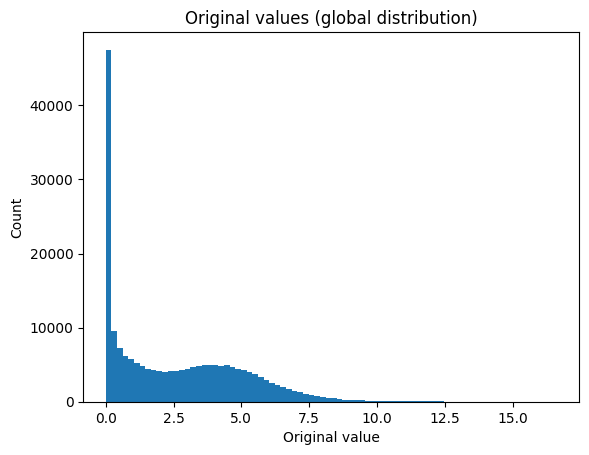

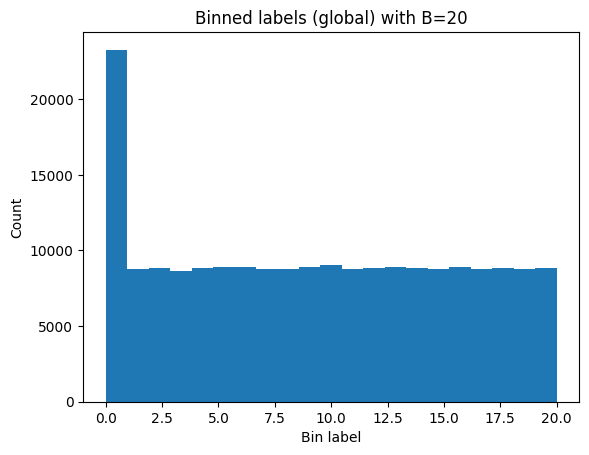

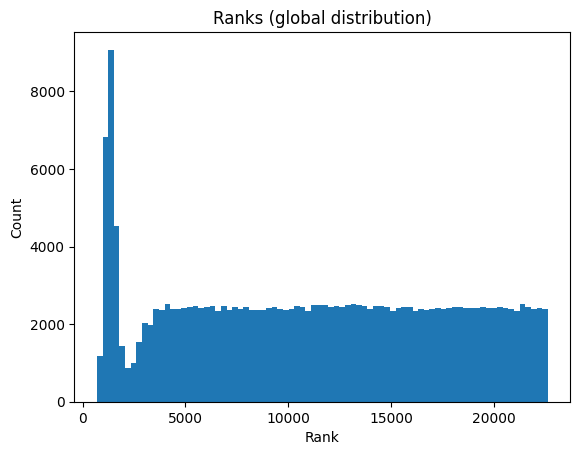

In [16]:
def sample_flat_values(df: pd.DataFrame, max_points: int = 200_000) -> np.ndarray:
    x = df.to_numpy().ravel()
    x = x[~np.isnan(x)]
    if x.size > max_points:
        idx = np.random.choice(x.size, size=max_points, replace=False)
        x = x[idx]
    return x

def plot_hist(values: np.ndarray, title: str, bins: int = 60, xlabel: str = "Value"):
    plt.figure()
    plt.hist(values, bins=bins)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.show()

# 1) Original values (global)
plot_hist(sample_flat_values(df), "Original values (global distribution)", bins=80, xlabel="Original value")

# 2) Binned labels (global)
plot_hist(sample_flat_values(binned), f"Binned labels (global) with B={B}", bins=B+1, xlabel="Bin label")

# 3) Ranks (global)
plot_hist(sample_flat_values(ranked), "Ranks (global distribution)", bins=80, xlabel="Rank")


## One-sample deep dive

Pick a sample ID (default: the first row). We’ll show:
- histogram of original values in that sample
- histogram of bin labels
- histogram of ranks
- scatter: original vs rank
- scatter: original vs bin label


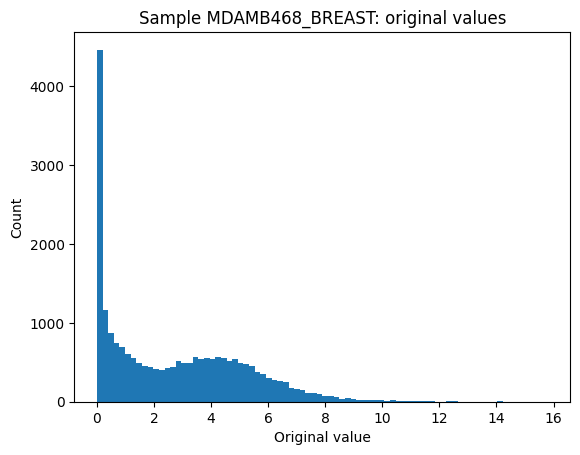

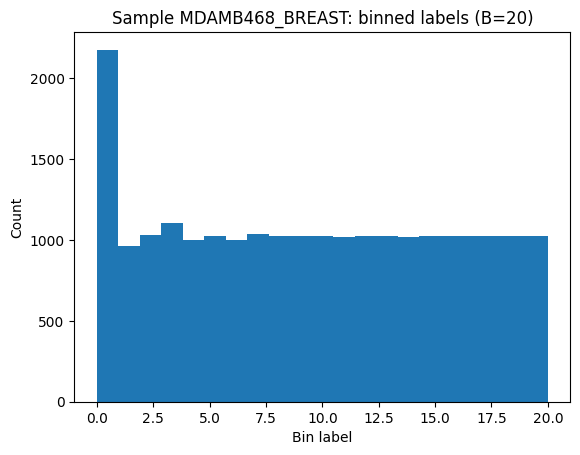

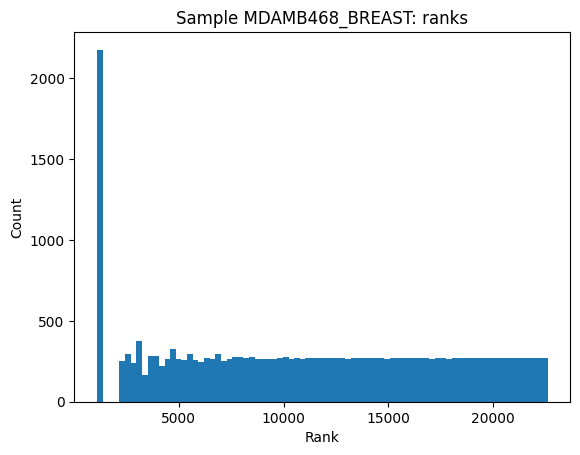

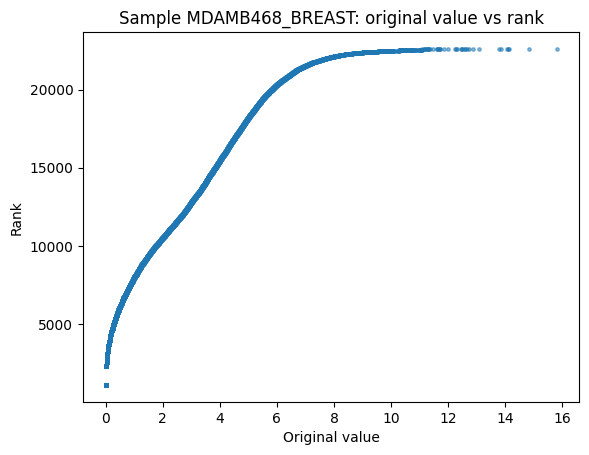

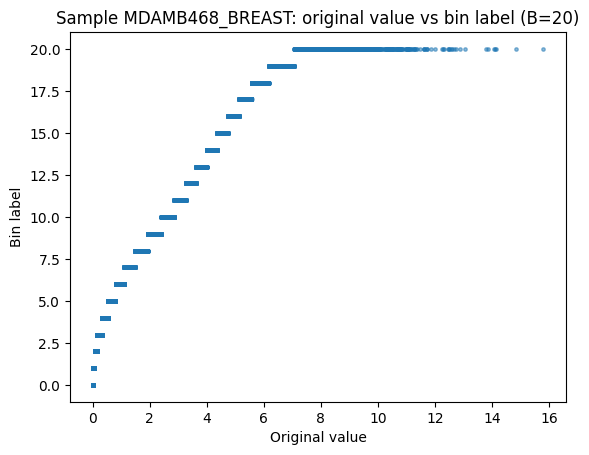

In [17]:
SAMPLE_ID = df.index[0]  # change this if you want a different sample
x = df.loc[SAMPLE_ID].to_numpy(dtype=float)
xb = binned.loc[SAMPLE_ID].to_numpy(dtype=float)
xr = ranked.loc[SAMPLE_ID].to_numpy(dtype=float)

mask = ~np.isnan(x)

plot_hist(x[mask], f"Sample {SAMPLE_ID}: original values", bins=80, xlabel="Original value")
plot_hist(xb[mask], f"Sample {SAMPLE_ID}: binned labels (B={B})", bins=B+1, xlabel="Bin label")
plot_hist(xr[mask], f"Sample {SAMPLE_ID}: ranks", bins=80, xlabel="Rank")

# Scatter: original vs rank
plt.figure()
plt.scatter(x[mask], xr[mask], s=6, alpha=0.5)
plt.title(f"Sample {SAMPLE_ID}: original value vs rank")
plt.xlabel("Original value")
plt.ylabel("Rank")
plt.show()

# Scatter: original vs bin
plt.figure()
plt.scatter(x[mask], xb[mask], s=6, alpha=0.5)
plt.title(f"Sample {SAMPLE_ID}: original value vs bin label (B={B})")
plt.xlabel("Original value")
plt.ylabel("Bin label")
plt.show()


## How much information is retained? (simple diagnostics)

- **Spearman correlation** between original values and ranks within each sample should be ~1
  (because rank is a monotonic transform).
- **Binning** is coarser, so the correlation is still positive but usually lower.

We compute a per-sample Spearman correlation using pandas.


In [18]:
def spearman_per_row(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    # Spearman correlation per row
    # (pandas corrwith works column-wise; for row-wise we do a loop; dataset sizes like 369x5113 are fine)
    out = []
    for idx in a.index:
        x = a.loc[idx]
        y = b.loc[idx]
        mask = x.notna() & y.notna()
        if mask.sum() < 3:
            out.append(np.nan)
        else:
            out.append(x[mask].corr(y[mask], method="spearman"))
    return pd.Series(out, index=a.index)

rho_rank = spearman_per_row(df, ranked)
rho_bin = spearman_per_row(df, binned)

print("Per-sample Spearman (original vs ranked):")
print(rho_rank.describe())

print("\nPer-sample Spearman (original vs binned):")
print(rho_bin.describe())


Per-sample Spearman (original vs ranked):
count    3.690000e+02
mean     1.000000e+00
std      5.758428e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Per-sample Spearman (original vs binned):
count    369.000000
mean       0.999141
std        0.000068
min        0.998969
25%        0.999096
50%        0.999135
75%        0.999183
max        0.999346
dtype: float64


## Demonstration of invariance to monotonic scaling (optional but illuminating)

If we apply a **monotonic transform** to a sample like:

\[ x' = 2x + 1 \]

then the **rank ordering** is unchanged (so ranks stay identical), while the raw distribution shifts.
This is a toy illustration of why ranking can be robust to certain dataset-specific scaling effects.


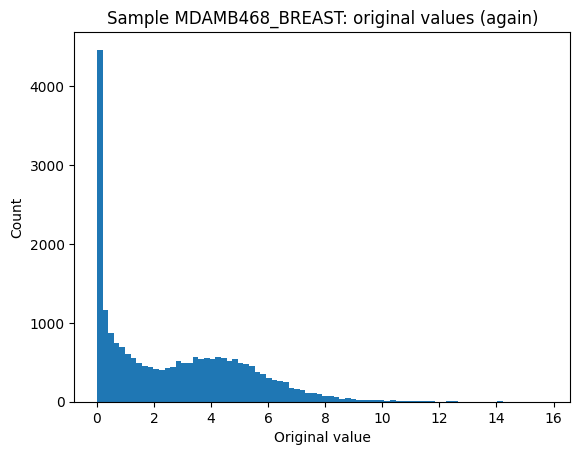

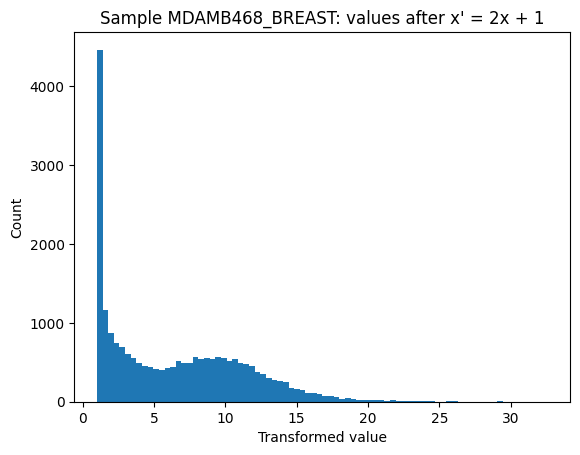

Fraction of features with identical rank after monotonic transform: 1.0000


In [19]:
x2 = 2*x + 1  # monotonic transform (keeps ordering)
mask2 = ~np.isnan(x2)

# Compare histograms
plot_hist(x[mask], f"Sample {SAMPLE_ID}: original values (again)", bins=80, xlabel="Original value")
plot_hist(x2[mask2], f"Sample {SAMPLE_ID}: values after x' = 2x + 1", bins=80, xlabel="Transformed value")

# Compare ranks (should match exactly except for NaNs)
r1 = pd.Series(x).rank(method="average", ascending=True)
r2 = pd.Series(x2).rank(method="average", ascending=True)
same = (r1[mask] == r2[mask]).mean()

print(f"Fraction of features with identical rank after monotonic transform: {same:.4f}")


## Save transformed outputs

This writes:
- `binned_B{B}.parquet` and `.csv`
- `ranked.parquet` and `.csv`

(Parquet is recommended for large matrices.)


In [20]:
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

binned_path_parquet = OUT_DIR / f"binned_B{B}.parquet"
ranked_path_parquet = OUT_DIR / "ranked.parquet"

binned.to_parquet(binned_path_parquet)
ranked.to_parquet(ranked_path_parquet)

# Optional CSV (larger)
binned.to_csv(OUT_DIR / f"binned_B{B}.csv")
ranked.to_csv(OUT_DIR / "ranked.csv")

print("Saved:")
print(" -", binned_path_parquet)
print(" -", ranked_path_parquet)


Saved:
 - outputs\binned_B20.parquet
 - outputs\ranked.parquet


## Notes / tips

- If your matrix is already z-scored, **ranking/binning** still works (it’s monotonic per sample).
- If you have many zeros, bin 0 can be meaningful (undetected vs low).
- **Choosing B**:
  - small B (e.g., 5–20): stronger robustness, less detail
  - large B (e.g., 50–200): closer to full ranking, more detail
- If you’re going to train models, compute any feature standardization using **training data only**.
